**Exercise Purpose**
- Use Gaussian filters to smooth noisy pupil coordinate data.
- Apply a derivative filter  [-1, 1]  to calculate rate of change (gradients) in the smoothed signals.
- Saccade Detection: Identify sudden eye movements (saccades) based on large changes in the gradients.
- Fixation Detection: Detect periods of stable gaze (fixations) and handle noise during these intervals.
- Noise Handling: Experiment with smoothing and balanced sigma values

In [68]:
import filtering_util
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# Filtering gaze data
This exercise introduces different techniques for processing and analyzing gaze data using filtering. In particular the exercise removing noise and identifying fixations and saccades in the signal. A _fixation_ is defined as an instance with little or no eye movement. A _saccade_ is an eye movement between two fixations as illustrated in [Figure 1](#fix_sacc) for an example (image from [researchGate](https://www.researchgate.net/publication/356796000_TECHNICAL_MANUALS_READING_STRATEGIES_OF_PRIMARY_TEACHER_TRAINESS/figures?lo=1)
).
<div class="has-text-centered">
<figure class="image is-inline-block" id="fix_sacc">

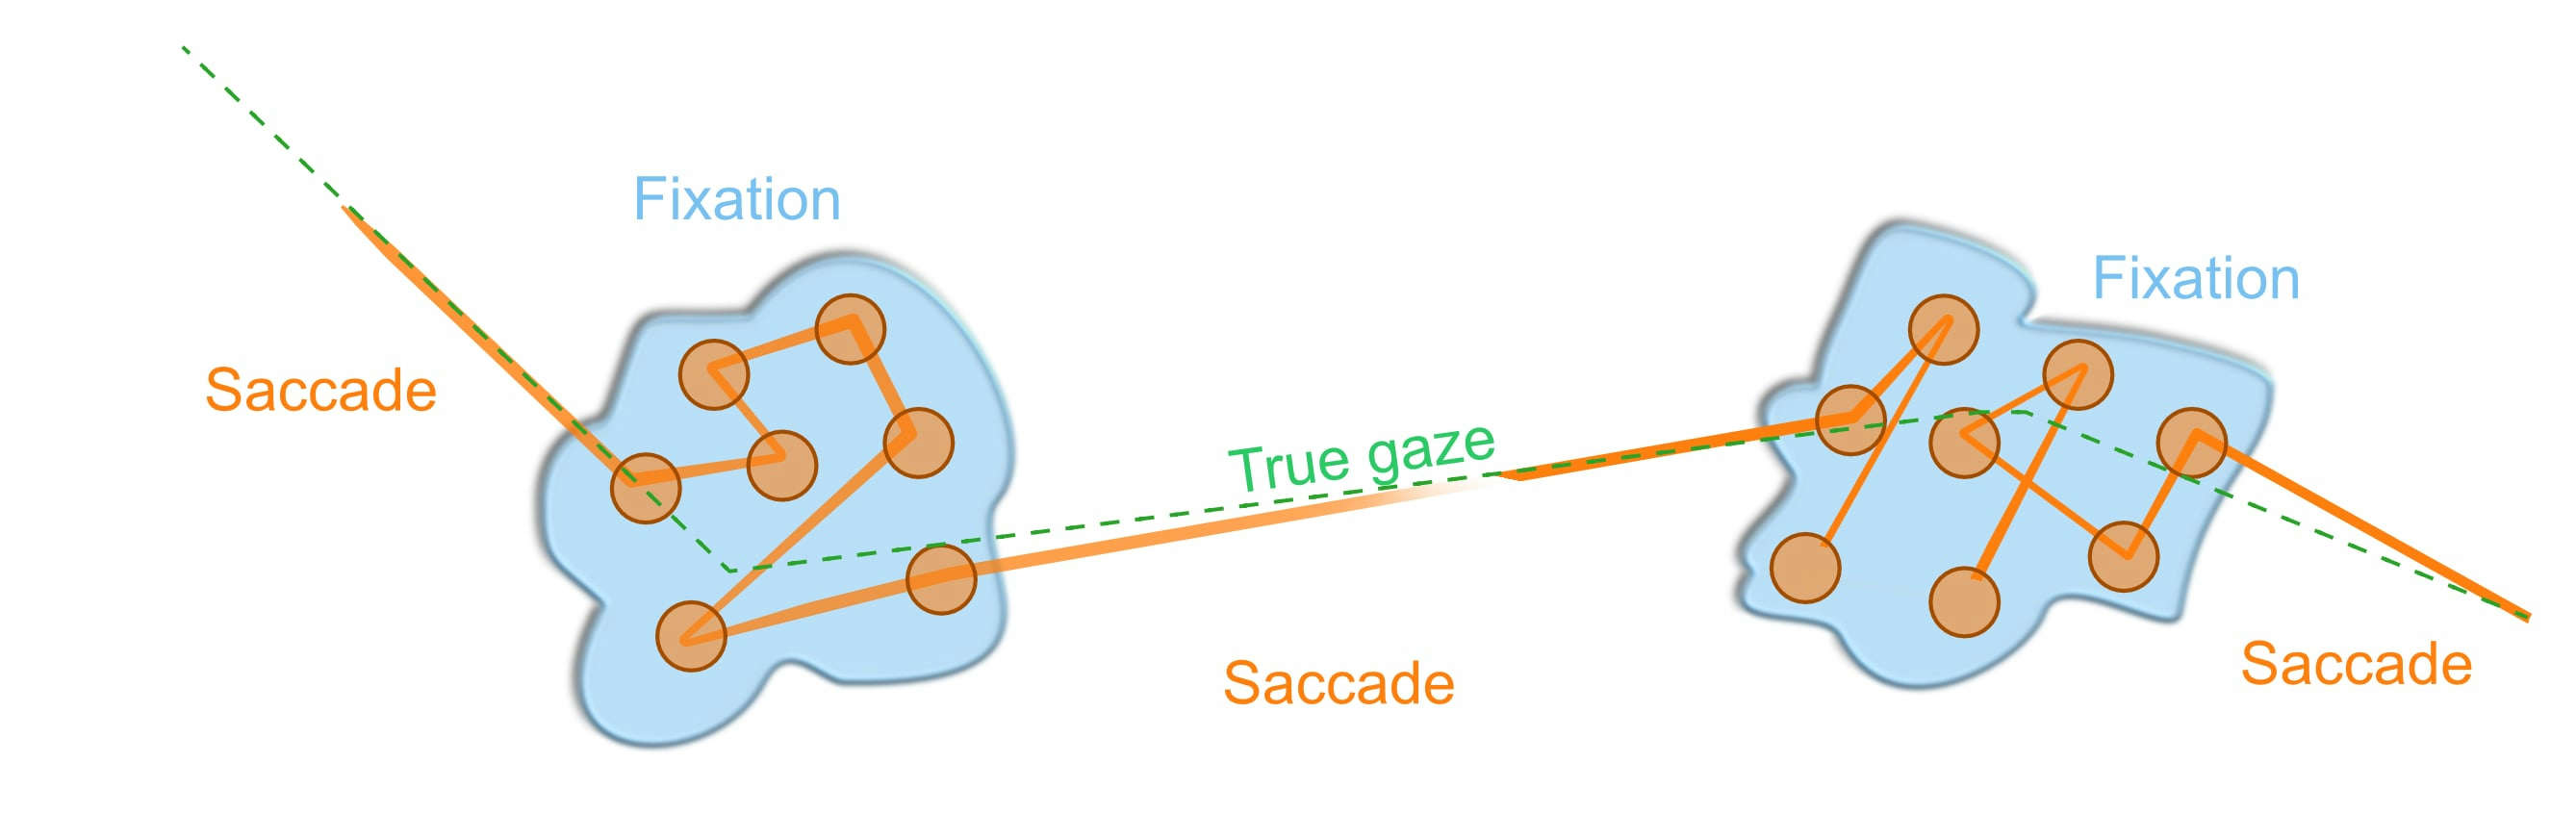

<figcaption class="figure-caption has-text-centered">Figure 1: Fixation and saccades in gaze data.
</figcaption>
</figure>
</div>
The visualizations presented throughout the exercise are based on data collected from `test_subject_3`
 using the `grid`
 pattern.
The exercise contains functions in the `filtering_util.py`
 file to create plots. 

<article class="message">
    <div class="message-body">
        <strong>List of individual tasks</strong>
        <ul style="list-style: none;">
            <li>
            <a href="#task_load_data">Task 1: Load the data</a>
            </li>
            <li>
            <a href="#task_gauss1">Task 2: Gaussian filter</a>
            </li>
            <li>
            <a href="#task_gauss2">Task 3: Implementing gaussian filter</a>
            </li>
            <li>
            <a href="#task_gauss3">Task 4: Reflect on applying gaussian filter</a>
            </li>
            <li>
            <a href="#task_gauss4">Task 5: Partial derivatives</a>
            </li>
            <li>
            <a href="#partial1">Task 6: Calculate the derivatives</a>
            </li>
            <li>
            <a href="#partial2">Task 7: Derivatives of a signal</a>
            </li>
            <li>
            <a href="#partial3">Task 8: Saccade detection</a>
            </li>
            <li>
            <a href="#partial4">Task 9: Saccade detection</a>
            </li>
            <li>
            <a href="#fixations1">Task 10: Fixation detection</a>
            </li>
            <li>
            <a href="#fixations2">Task 11: Visualization of signals</a>
            </li>
            <li>
            <a href="#fixation3">Task 12: Noise handling during fixations</a>
            </li>
            <li>
            <a href="#fixation4">Task 13: Frame grouping</a>
            </li>
            <li>
            <a href="#results1">Task 14: Analyse results</a>
            </li>
            <li>
            <a href="#results2">Task 15: Reflect</a>
            </li>
            <li>
            <a href="#owndata">Task 16: Combined signal</a>
            </li>
            <li>
            <a href="#combined1">Task 17: Combined signal</a>
            </li>
            <li>
            <a href="#combined2">Task 18: Reflect</a>
            </li>
        </ul>
    </div>
</article>

**Note:** Although the number of tasks is substantial, each requires minimal programming effort, with many tasks primarily necessitating reflection on the outcomes.


---
**Task 1 (easy): Load the data👩‍💻**
1. Run the cell to visualize the `grid`
 pattern of `test_subject_3`
.
**Note:** The code is loading the data from the folder of week 6. Alternatively you can copy the data to the folder of this exercise and change the file path accordingly.




---

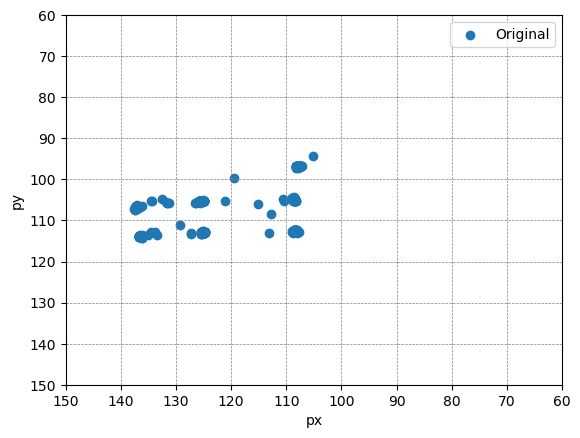

In [69]:
test_subject = 'test_subject_3'

csv_file =f'../week8/data/output/{test_subject}/grid/pupil_coordinates.csv'

pupil_coor= filtering_util.load_csv1(csv_file)

filtering_util.plot_pupil_coor(pupil_coor['px'], pupil_coor['py'], 'Original')
plt.show()

The next task involves visualizing the pupil coordinates signals `px`
 and `py`
 for the gaze `grid`
 pattern. In this task, a $1D$ Gaussian filter will be applied to smooth the signals individually. [Figure 2](#gauss) illustrates the Gaussian $1D$ filters and the corresponding filtered signal. The cell below convolves a Gaussian filter to gaze data. 
<div class="has-text-centered">
<figure class="image is-inline-block" id="gauss">

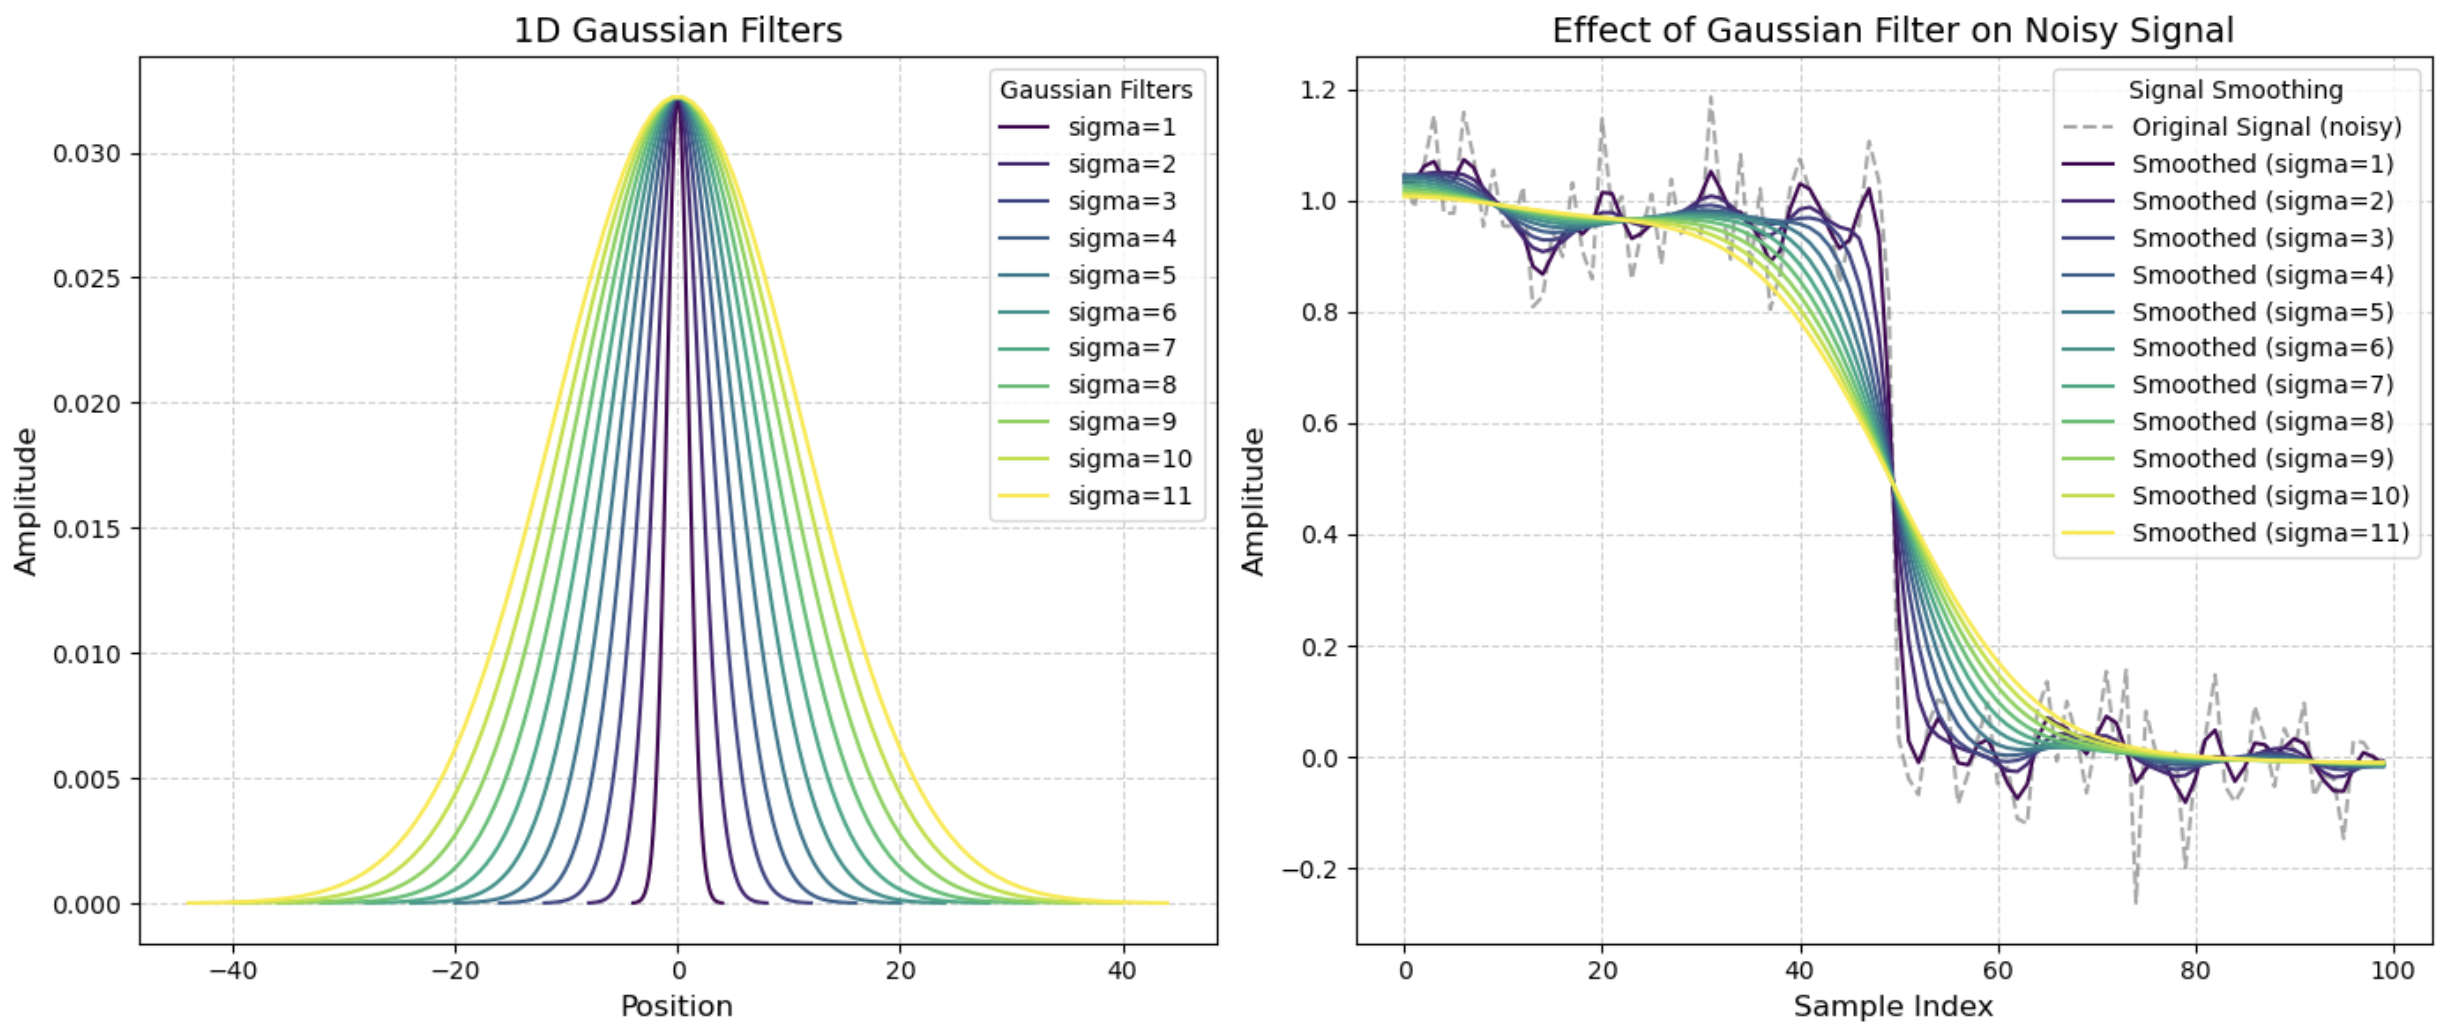

<figcaption class="figure-caption has-text-centered">Figure 2: Left: Shows the shape of the Gaussian filter for each value of sigma. Right: Demonstrates the effect of smoothing the noisy signal with each Gaussian filter.
</figcaption>
</figure>
</div>

---
**Task 2 (easy): Gaussian filter👩‍💻**
1. Reflect on the effect of applying a Gaussian filter to the data and how this can affect the subsequent proccessing of the gaze signal.


---

In [70]:
#Write your reflections here...
"""
Noise Reduction: Smooths the signal, reducing measurement noise and small involuntary movements.
Improved Signal Quality: Enhances overall data quality by softening abrupt changes and spikes.
Better Data Interpretation: Aids in more accurate gaze pattern analysis by clarifying focus areas.
Enhanced Algorithm Performance: Improves the accuracy of algorithms detecting fixations and saccades by providing cleaner input data.
Parameter Sensitivity: Effectiveness depends on the sigma value; larger sigma increases smoothness but may blur details, while smaller sigma retains details but may not reduce noise sufficiently.
Edge Artifacts: Potential introduction of artifacts at the data sequence edges due to filter boundary effects.
Real-time Processing Trade-offs: Involves balancing between smoothing effectiveness and processing delay in real-time applications.
"""

'\nNoise Reduction: Smooths the signal, reducing measurement noise and small involuntary movements.\nImproved Signal Quality: Enhances overall data quality by softening abrupt changes and spikes.\nBetter Data Interpretation: Aids in more accurate gaze pattern analysis by clarifying focus areas.\nEnhanced Algorithm Performance: Improves the accuracy of algorithms detecting fixations and saccades by providing cleaner input data.\nParameter Sensitivity: Effectiveness depends on the sigma value; larger sigma increases smoothness but may blur details, while smaller sigma retains details but may not reduce noise sufficiently.\nEdge Artifacts: Potential introduction of artifacts at the data sequence edges due to filter boundary effects.\nReal-time Processing Trade-offs: Involves balancing between smoothing effectiveness and processing delay in real-time applications.\n'


---
**Task 3 (easy): Implementing gaussian filter👩‍💻**
1. Study the function `apply_gauss`
 in the cell below.
2. Apply a Gaussian filter to the gaze data individually for `px`
and `py`
 signals. Use the function `plot_x_and_y`
 from `filtering_util.py`
 to visualize the result.    - The function takes two arrays of data as parameters.




---

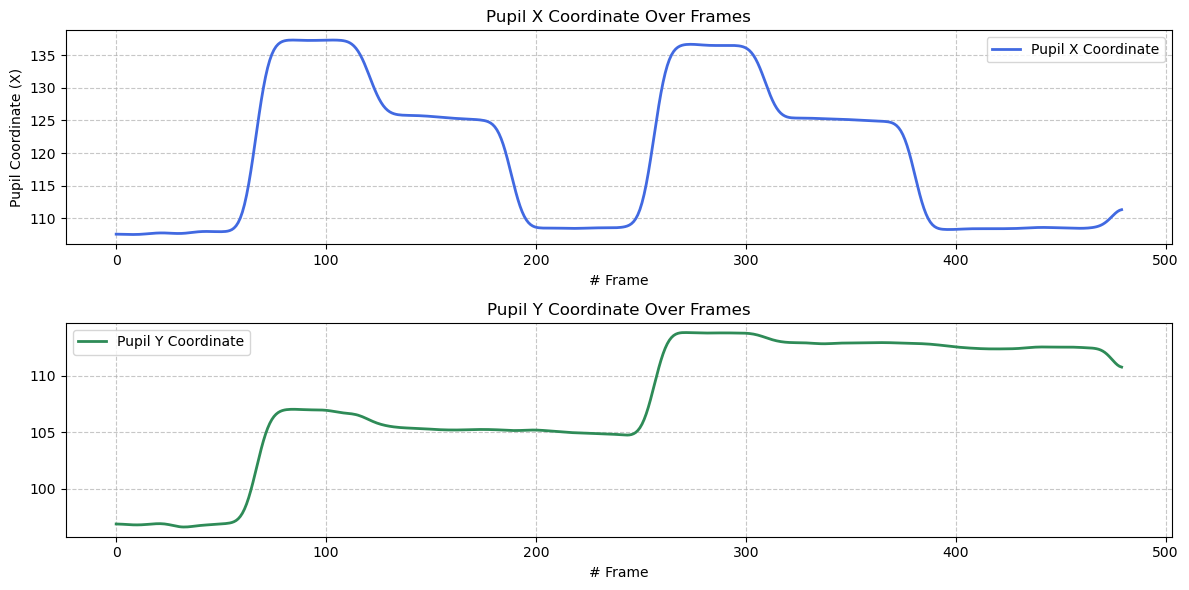

In [144]:
def apply_gauss(data, sigma = 5):
    filtered = gaussian_filter1d(data, sigma=sigma, order = 0)
    return filtered



px = np.asarray(pupil_coor['px'])
py = np.asarray(pupil_coor['py'])

# Write your implementation
filtered_x = apply_gauss(px)
filtered_y = apply_gauss(py)

filtering_util.plot_x_and_y(filtered_x, filtered_y)


---
**Task 4 (easy): Reflect on applying gaussian filter👩‍💻💡**
1. Experiment with the `sigma`
 parameter, which value of sigma removes the noise, but maintains the signal? 
2. For which value of `sigma`
 does the important features of the signal start to disappear?


---

In [94]:
#Write your reflections here...
# Too low it shows many small fluctuations, too high it blurs the data. 
# 5 seems to be a good value for this data.

## Partials derivatives

---
**Task 5 (easy): Partial derivatives💡**
1. Recall from the lecture the partial derivatives of a signal calculated by convolving using the filter `[-1, 1]`
. What would be the result of applying the derivative filter to data smoothed by a Gaussian filter? Use the following questions to guide your answers:    - Why does this filter find the derivative of the signal?
    - Which information is gained by applying such filter to gaze data?
    - How can the output be used for further processing?
    - What is the influence of the `sigma`
 value in the Gaussian the filter when finding the partial derivatives?




---

In [95]:
#Write your reflections here...
"""
Why does this filter find the derivative of the signal?
When applied to a data sequence, it computes the difference between consecutive elements. 
This difference approximates the derivative, representing how much the signal changes from one point to the next, 
effectively highlighting the rate of change in the gaze position.

Which information is gained by applying such a filter to gaze data?
It can find saccades (rapid changes in gaze position, high or low gradiant values)
and fixations (periods of stable gaze, zero gradiant values).

How can the output be used for further processing?
The derivatives can be used to:
Detect saccades: High or low gradients indicate rapid eye movements between fixations.
Identify fixations: Low or 0 velocities indicate where the eye lingers

What is the influence of the sigma value in the Gaussian filter when finding the partial derivatives?
The sigma value in the Gaussian filter affects the smoothness of the data before the derivative is calculated. 
A larger sigma value leads to more smoothing, which can suppress high-frequency noise and minor fluctuations, resulting in a cleaner signal but potentially obscuring fast, subtle movements. 
Conversely, a smaller sigma value preserves more detail, which can be useful for detecting rapid changes but may also retain more noise. 
The choice of sigma therefore needs to be balanced based on the characteristics of the eye movement being analyzed and the noise level in the data.
"""

'\nWhy does this filter find the derivative of the signal?\nWhen applied to a data sequence, it computes the difference between consecutive elements. \nThis difference approximates the derivative, representing how much the signal changes from one point to the next, \neffectively highlighting the rate of change in the gaze position.\n\nWhich information is gained by applying such a filter to gaze data?\nIt can find saccades (rapid changes in gaze position, high or low gradiant values)\nand fixations (periods of stable gaze, zero gradiant values).\n\nHow can the output be used for further processing?\nThe derivatives can be used to:\nDetect saccades: High or low gradients indicate rapid eye movements between fixations.\nIdentify fixations: Low or 0 velocities indicate where the eye lingers\n\nWhat is the influence of the sigma value in the Gaussian filter when finding the partial derivatives?\nThe sigma value in the Gaussian filter affects the smoothness of the data before the derivative

The following task is about implementing a method to find derivatives a signal using the filter $[-1, 1]$. 
The function `plot_x_and_y_complete`
 from `filter_util.py`
 takes two dictionaries one for each coordinates and plots the signals. The dictionaries should contain keys value pairs of the original and processed signal. 

---
**Task 6 (easy): Calculate the derivatives👩‍💻**
1. Complete the function `get_partial_derivatives`
 to apply the derivative filter to a signal and return the absolute value of the result. Use [np.convolve](https://numpy.org/doc/2.0/reference/generated/numpy.convolve.html)
 for convolution. The **absolute value** of the derivative is used as only the rate of change is of interest. 


---

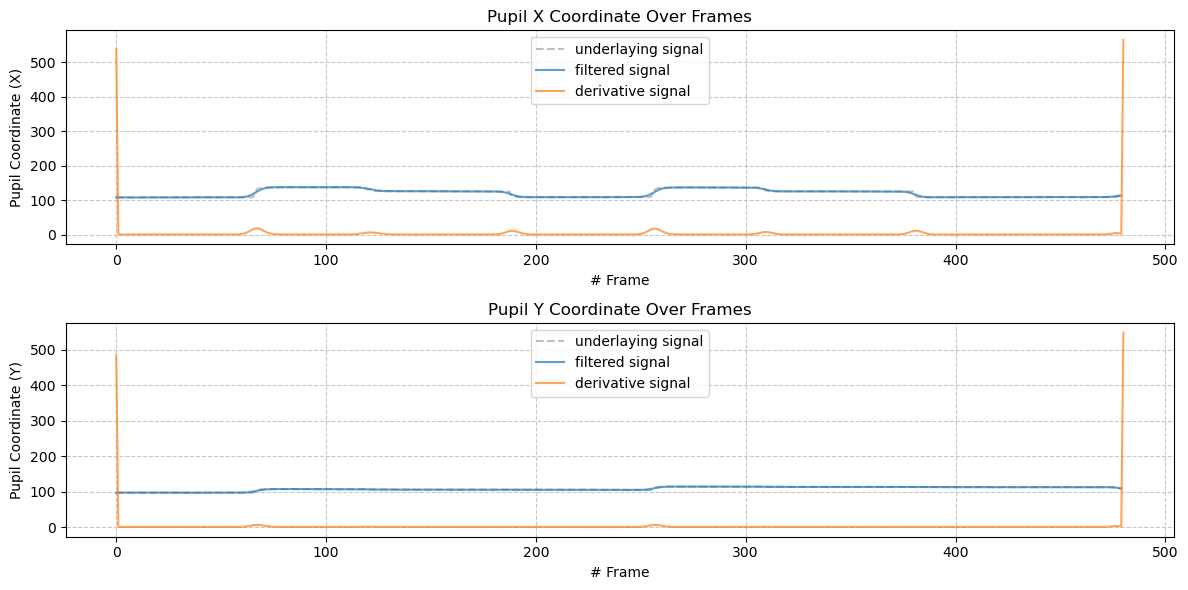

In [96]:
def get_partial_derivatives(data):
    """
    Convolve 1D data with a [-1, 1] filter.

    Args:
        data (numpy array): 1D array of data.

    Returns:
        numpy array: Convolved result.
    """
    return np.abs(np.convolve(data, [-1, 1]))

der_x = get_partial_derivatives(filtered_x)
der_y = get_partial_derivatives(filtered_y)

x_collected = {'underlaying': px, 'filtered': filtered_x, 'derivative': der_x}
y_collected = {'underlaying': py, 'filtered': filtered_y, 'derivative': der_y}

filtering_util.plot_x_and_y_complete(x_collected, y_collected)


---
**Task 7 (easy): Derivatives of a signal💡**
1. Inspect the plots above and reflect on the relation between the original signals, the filtered and the derivative of the filtered signals. In your reflections you may include:    - What charateristics in the gaze data do the peaks and plateaus encapsulate, use the data collection session to elaborate. 
    - What behaviour is expected for the `x`
 coordinate of the pupil?
    - What behaviour is expected for the `y`
 coordinate of the pupil?
    - What would happen with these if if the pattern was changed?




---

In [97]:
#Write your reflections here...
"""
Relation between Original, Filtered, and Derivative Signals:
The original signal shows the raw gaze data with all its fluctuations.
The filtered signal represents the smoothed version, reducing noise and highlighting the true movement trends.
The derivative of the filtered signal highlights the points of change in the gaze movement, 
specifically identifying where significant movements occur (saccades) or where the movement stops (fixations).

Characteristics Captured by Peaks and Plateaus:
Peaks in the derivative indicate rapid changes in gaze direction or speed, typically marking the beginning or end of a saccade.
Plateaus or zero-values in the derivative suggest periods where there is little to no change in gaze direction, 
likely corresponding to fixations where the eye rests on a particular point.

Expected Behaviors:
For the x-coordinate of the pupil, you expect changes that reflect horizontal movement. Peaks in the derivative might indicate rapid horizontal shifts.
For the y-coordinate, changes represent vertical movements.
"""

'\nRelation between Original, Filtered, and Derivative Signals:\nThe original signal shows the raw gaze data with all its fluctuations.\nThe filtered signal represents the smoothed version, reducing noise and highlighting the true movement trends.\nThe derivative of the filtered signal highlights the points of change in the gaze movement, \nspecifically identifying where significant movements occur (saccades) or where the movement stops (fixations).\n\nCharacteristics Captured by Peaks and Plateaus:\nPeaks in the derivative indicate rapid changes in gaze direction or speed, typically marking the beginning or end of a saccade.\nPlateaus or zero-values in the derivative suggest periods where there is little to no change in gaze direction, \nlikely corresponding to fixations where the eye rests on a particular point.\n\nExpected Behaviors:\nFor the x-coordinate of the pupil, you expect changes that reflect horizontal movement. Peaks in the derivative might indicate rapid horizontal shifts

The following task are about detecting events (fixations and saccades) in eye signals using derivative filters.

---
**Task 8 (easy): Saccade detection👩‍💻**
1. Complete the function `saccade_detection`
.     - The function should identify indices for large eye movement changes called _saccades_ using the derivatives of the smoothed signal.


2. Use the function `saccade_detection`
 to detect events in the derivative signal of the filtered signal of both `px`
 and `py`



---

In [136]:
def saccade_detection(der):
    """
    Detects saccades (non-zero changes) in the derivative data.
    Parameters:
    der (1 x N numpy array): Representing the derivative of the signal.
    Returns:
    saccades (list): A list of indices where there are non-zero changes (saccades) in `x_dev`.
    """
    saccades = []
    # Write your implementation
    for i in range(len(der)):
        if der[i] > 2:
            saccades.append(i)
    return saccades


x_saccades = saccade_detection(der_x)
y_saccades = saccade_detection(der_y)


---
**Task 9 (easy): Saccade detection👩‍💻**
1. Run the cell below to visualize the detected saccades.


---

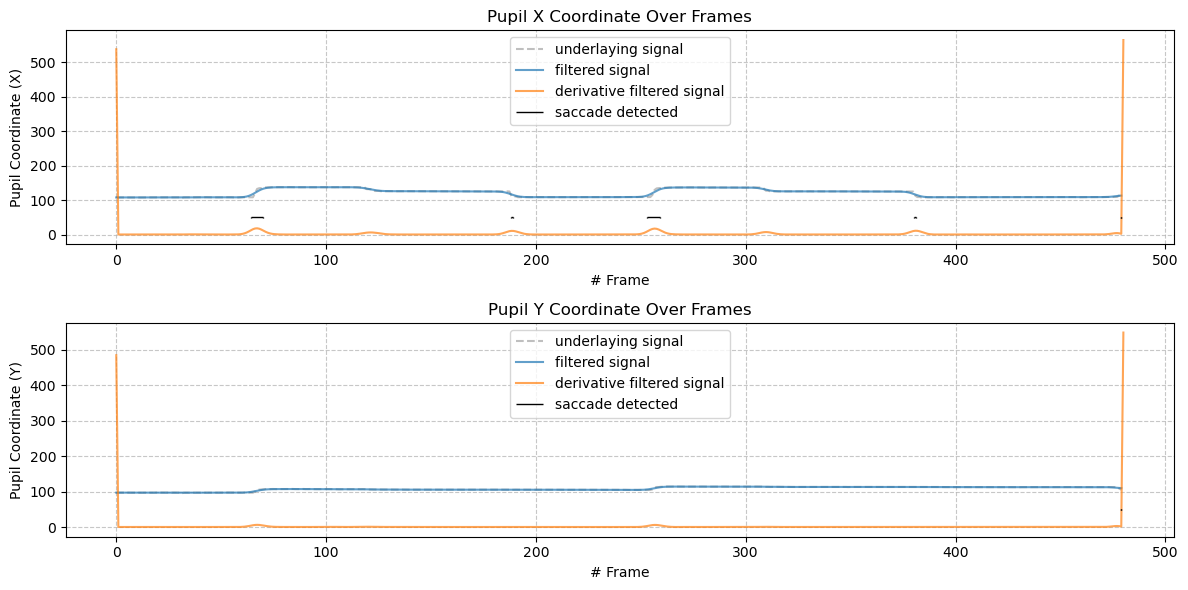

In [137]:
x_saccade = {'underlaying': px, 'filtered': filtered_x, 'derivative filtered': der_x, 'saccade': x_saccades}
y_saccade = {'underlaying': py, 'filtered': filtered_y, 'derivative filtered': der_y, 'saccade': y_saccades}

filtering_util.plot_x_and_y_complete(x_saccade, y_saccade)


---
**Task 10 (easy): Fixation detection👩‍💻**
1. Complete the function `fixation_filtering`
 to handle noise during fixations. Select an appropriate method discussed in the lectures or draw inspiration from the experimental setup to handle noise during fixations.
2. Use the function `fixation_filtering`
 to remove the noise in the filtered signals and return cleaned signals for both `px`
 and `py`
 . 
3. Use the function `get_partial_derivatives`
 to calculate the partial derivatives of the cleaned signals.
4. Use the function `saccade_detection`
 to detect events in the derivative signal of the cleaned signal of both `px`
 and `py`
.


---

In [138]:
def fixation_filtering(px, py, x_saccades, y_saccades):
    """
    Removes noise from the input data based on detected saccades. If a spike is detected
    at a given index, the previous valid value is used to replace the current value.
    Parameters:
        px (1 x N nupy array): Representing the x coordinates (input signal).
        py (1 x N nupy array): Representing the y coordinates (input signal).
        x_saccades (list): A list of indices where saccades are detected in the x direction.
        y_saccades (list): A list of indices where saccades are detected in the y direction.
    Returns:
    px_new (list): A list of the cleaned x coordinates.
    py_new (list): A list of the cleaned y coordinates.
    """
    px_cleaned = [] 
    py_cleaned = []
    # Write your implementation
    for i in range(len(px)):
        if i in x_saccades:
            px_cleaned.append(px[i-1])
        else:
            px_cleaned.append(px[i])
        if i in y_saccades:
            py_cleaned.append(py[i-1])
        else:
            py_cleaned.append(py[i])
    return px_cleaned, py_cleaned



cleaned_px, cleaned_py = fixation_filtering(px, py, x_saccades, y_saccades)
der_x_cleaned = get_partial_derivatives(cleaned_px)
der_y_cleaned = get_partial_derivatives(cleaned_py)
x_saccades_cleaned = saccade_detection(der_x_cleaned)
y_saccades_cleaned = saccade_detection(der_y_cleaned)


---
**Task 11 (easy): Visualization of signals👩‍💻**
1. Run the cell below to visualize the fixations and saccades.


---

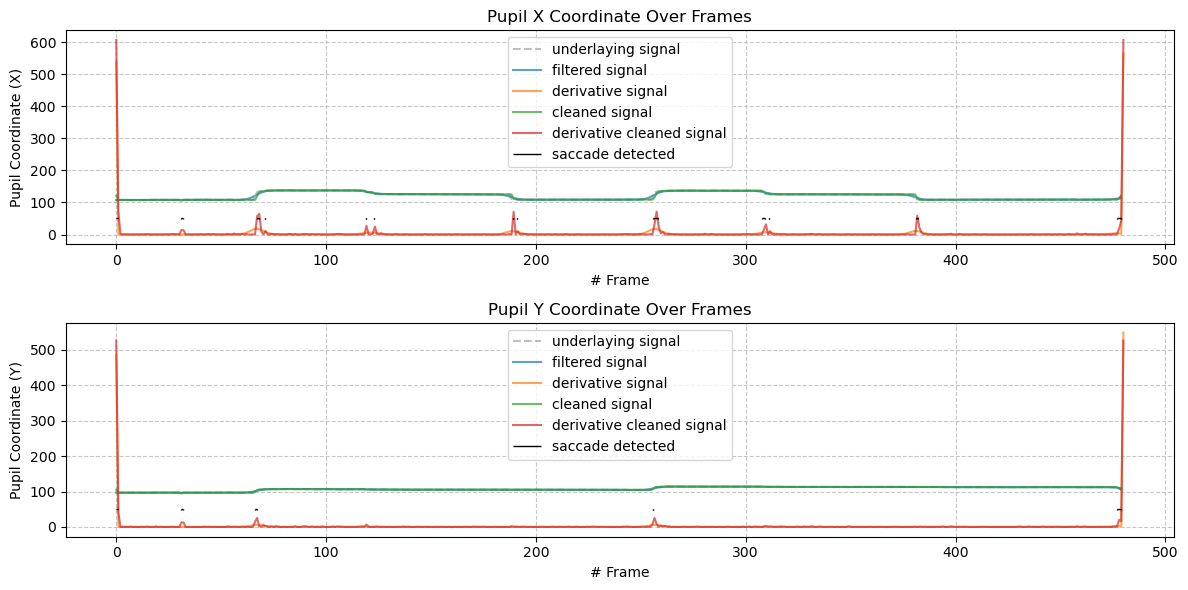

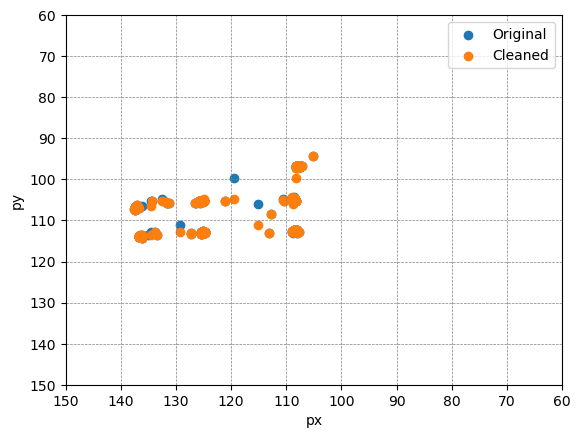

In [139]:
x_collected['cleaned'] = cleaned_px
y_collected['cleaned'] = cleaned_py

x_collected['derivative cleaned'] = der_x_cleaned
y_collected['derivative cleaned'] = der_y_cleaned

x_collected['saccade detected'] = x_saccades_cleaned
y_collected['saccade detected'] = y_saccades_cleaned

filtering_util.plot_x_and_y_complete(x_collected, y_collected, 5) #5 is a scaling factor on the values of the derivative for display purposes
filtering_util.plot_pupil_coor(px, py, 'Original')
filtering_util.plot_pupil_coor(cleaned_px, cleaned_py, 'Cleaned')
plt.show()


---
**Task 12 (easy): Noise handling during fixations💡**
1. Reflect on the assumptions of your method for handling noise during fixations in [Task 10](#fixations1). What are the advantages and limitations of your approach if any?
2. Reflect on other strategies that you could use for handling the noise and outliers in the gaze data.


---

In [140]:
#Write your reflections here...

The next step is to utilize the charateristics of the derivative of the smoothed signal to detect the frames (pupil coordinates) corresponding to each screen calibration point, so the data can be sorted in corresponding input and label pairs.

---
**Task 13 (easy): Frame grouping👩‍💻**
1. Complete the function `get_frames_pupil_movement`
. The function should:    - Construct a dictionary where the keys represent the calibration point numbers (e.g., '0', '1', ..., '8'), and the associated values are tuples consisting of the start and end frame numbers.


2. Use the function `get_frames_pupil_movement`
 to determine the sections pupil corrdinate sections belonging to each calibration coordinate.


---

In [141]:
def get_frames_pupil_movement(cleaned_der, data):
    """
    Identifies segments of pupil movement based on changes in the cleaned derivative.
    Parameters:
        cleaned_der (list or numpy array): A 1D array of the derivative values of the cleaned data, indicating changes in pupil position over time.
        data (list or numpy array): The original data corresponding to the pupil movement.

    Returns:
        dict ( {string: tuple(int, int)} ): A dictionary where the keys are calibration point numbers (as strings) and the values are tuples
              containing the start and end frame numbers for each segment.
    """
    frames = {}
# Write your implementation

filtering_util.plot_pupil_coordinates(frames, px, py, cleaned_px, cleaned_py)

NameError: name 'frames' is not defined

## Analyzing results
In the following tasks the results of the filtering will be analyzed using _mean_, _variance_ and _covariance_ at each calibration target for both raw data and filtered data.

---
**Task 14 (easy): Analyse results👩‍💻**
1. Run the cell below to visualize the mean, variance and covariance of the data before and after processing.


---

In [0]:
filtering_util.plot_statistics_comparison(px, py, cleaned_px, cleaned_py, frames)


---
**Task 15 (easy): Reflect💡**
1. Reflect on the results visualized in the plots.    - What effect does cleaning the data have on the mean and variance?         - Use your reflection from [Task 12](#fixation3) and reevaluate your choice of strategy, has it changes the underlaying signal in terms of mean and variance? Why? Why not? 


    - If any target points stands out, why? Relate to the experiment setup and the pupil detection method. 




---## Inspecting own data

---
**Task 16 (medium): Combined signal👩‍💻💡**
1. Go back to [Task 1](#task_load_data) and update the folder path to target the `grid`
 pattern of your own data.
2. Rerun the steps above.
3. Reflect on how well does the method generalizes to this dataset. You may use the following questions to guide your answers?    - How do the results differ from the ones of `test_subject_3`
?
    - Is it possible to reuse the same parameters or do they need to be updated?
    - Has the experimental setup any influence on the methods ability to generalizable? Why/why not?




---

In [0]:
# Write your reflections here...

## Event detection using gradients
In this task you will explore the combined signal (changes in x and y direction simultainously) and use the gradient for event detection. Recall the definition for the gradient of the function $f(x,y)$:

$$

\nabla f(x, y) = \left( \frac{\partial f(x,y)}{\partial x}, \frac{\partial f(x,y)}{\partial y} \right)


$$

You will use the gradient magnitude, the length of the gradient defined by:

$$
||\nabla f(x, y)|| = \sqrt{\Big(\frac{\partial f(x,y)}{\partial x}\Big)^2 + \Big(\frac{\partial f(x,y)}{\partial y} \Big)^2}
$$

---
**Task 17 (easy): Combined signal👩‍💻**
1. Complete the functions:    - `gradient_mangitude`
: The function should calculate the gradient magnitude of a $2D$ signal given `x`
 and `y`
.




---

In [0]:
def gradient_mangitude(x,y):
    """
    Calculates the gradient mangitude in a 2D space.
    Args:
        x (N x 1 numpy array): Array of x coordinates.
        y (N x 1 numpy array): Array of y coordinates.
    
    Returns:
        (N x 1 numpy array): The Euclidean distance from the origin to the point (x, y).
    """
    # Write your implementation

magnitude = gradient_mangitude(der_x, der_y)
magnitude_cleaned = gradient_mangitude(der_x_cleaned, der_y_cleaned)

collected_signal = {}
collected_magnitude = {}
collected_signal['x'] = px
collected_signal['y'] = py
collected_signal['x cleaned'] = cleaned_px
collected_signal['y cleaned'] = cleaned_py
collected_magnitude['magnitude of gradient'] = magnitude
collected_magnitude['magnitude of gradient cleaned'] = magnitude_cleaned



filtering_util.plot_x_and_y_complete(collected_signal, collected_magnitude, 5) #5 is a scaling factor on the values of the derivative for display purposes


---
**Task 18 (easy): Reflect💡**
1. Reflect on the benefit of using the combined signal compared to using the two individual signals.


---

In [0]:
# Write your reflection here...
"""
Holistic View: The gradient magnitude combines changes in both x and y directions, providing a complete picture of how much and how quickly the gaze is changing, irrespective of the direction. This is crucial for detecting events where movement magnitude is more important than direction.

Simplicity in Thresholding: Event detection can be simplified by setting a single threshold on the gradient magnitude, rather than dealing with complex multi-dimensional thresholding conditions.

Noise Robustness: Combining the signals can help mitigate the effect of noise in one component by averaging out fluctuations across dimensions.

Enhanced Event Detection: Sharp increases in the gradient magnitude can indicate rapid movements (saccades), while lower values suggest slower movements or fixations, aiding in more accurate and robust event classification.
"""